# 1. Are goals per match Poisson distributed?

If goals arrive as a Poisson process with a constant rate, the number of goals in a 90-minute match follows a Poisson distribution. This notebook tests that claim on 296 World Cup matches (2014, 2018, 2022, 2026) before looking at any goal times.

In [1]:
import sys
sys.path.insert(0, "../src")

import numpy as np
import pandas as pd
import scipy.stats as st
import matplotlib.pyplot as plt
from load import load

matches, goals = load("../data/worldcup.json")

# goals per match in regulation time
x = (matches.ft1 + matches.ft2).to_numpy()
n = len(x)
print(f"{n} matches, {x.sum()} goals in regulation")

296 matches, 797 goals in regulation


## 1.1 Estimate the rate

In [ ]:
lam = x.mean()
var = x.var(ddof=1)

print(f"mean (lambda hat): {lam:.3f} goals per match")
print(f"sample variance:   {var:.3f}")
print(f"variance / mean:   {var / lam:.3f}   (a Poisson would give about 1)")

mean (lambda hat): 2.693 goals per match
sample variance:   3.251
variance / mean:   1.207   (a Poisson would give about 1)


## 1.2 Observed against expected

Count how many matches had 0, 1, 2, ... goals, and compare with what a Poisson(λ) predicts: `n * P(X = k)`.

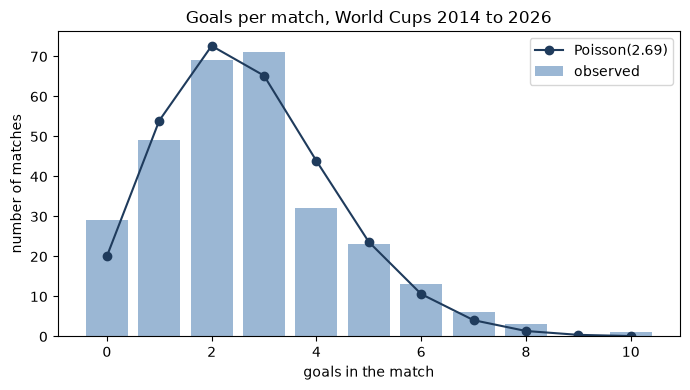

In [5]:
ks = np.arange(0, x.max() + 1)
observed = np.bincount(x, minlength=len(ks))
expected = n * st.poisson.pmf(ks, lam)

fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(ks, observed, color="#9bb7d4", label="observed")
ax.plot(ks, expected, "o-", color="#1f3b5c", label=f"Poisson({lam:.2f})")
ax.set_xlabel("goals in the match")
ax.set_ylabel("number of matches")
ax.set_title("Goals per match, World Cups 2014 to 2026")
ax.legend()
fig.tight_layout()
fig.savefig("../figures/01_goals_per_match.png", dpi=150)
plt.show()

## 1.3 Chi-square goodness-of-fit test

**Null hypothesis:** goals per match are Poisson(λ).

In [ ]:
cut = 6                                   # last bin is "6 or more" bc of assumptions
obs_binned = np.append(observed[:cut], observed[cut:].sum())
exp_binned = n * st.poisson.pmf(np.arange(cut), lam)
exp_binned = np.append(exp_binned, n - exp_binned.sum())

table = pd.DataFrame({
    "goals": [str(k) for k in range(cut)] + [f"{cut}+"],
    "observed": obs_binned,
    "expected": exp_binned.round(1),
})
print(table.to_string(index=False))

chi2 = ((obs_binned - exp_binned) ** 2 / exp_binned).sum()
dof = len(obs_binned) - 1 - 1 # estimated from same data
p_chi2 = st.chi2.sf(chi2, dof)
print(f"\nchi-square = {chi2:.2f}, df = {dof}, p = {p_chi2:.3f}")

goals  observed  expected
    0        29      20.0
    1        49      54.0
    2        69      72.6
    3        71      65.2
    4        32      43.9
    5        23      23.6
   6+        23      16.6

chi-square = 10.85, df = 5, p = 0.054


## 1.4 Dispersion test

The chi-square test looks for *any* departure from the Poisson shape, but we did notice that variance / mean is not equal to one, so we conduct a dispersion test to ask if the variance bigger than the mean. 

Under the null, `(n - 1) * variance / mean` follows a chi-square distribution with `n - 1` degrees of freedom. 

In [7]:
D = (n - 1) * var / lam
p_disp = st.chi2.sf(D, n - 1)
print(f"dispersion statistic = {D:.1f}, df = {n - 1}, p = {p_disp:.4f}")

dispersion statistic = 356.2, df = 295, p = 0.0084


## 1.5 Where is the misfit?

 Which bins have more matches than the Poisson predicts, and which have fewer?

In [8]:
table["difference"] = (table.observed - table.expected).round(1)
print(table.to_string(index=False))

goals  observed  expected  difference
    0        29      20.0         9.0
    1        49      54.0        -5.0
    2        69      72.6        -3.6
    3        71      65.2         5.8
    4        32      43.9       -11.9
    5        23      23.6        -0.6
   6+        23      16.6         6.4


## Conclusion

Goals per match are close to Poisson but not quite. The mean is 2.69 goals per match and the variance is 3.25, about 20% larger than a Poisson allows.

The two tests we ran disagree since chi-square goodness-of-fit only barely does not reject (chi-square = 10.85, df = 5, p = 0.054), while the dispersion test squarely does (p = 0.008), which makes sense, because the dispersion test was chosen for its power in measuring our specific issue. 

The misfit, then, is in the extremes: 29 goalless matches against 20 expected, and 23 matches with six or more goals against 17 expected, along with a spike in mismatch with 4-goal games. This is the pattern a mixture produces. If each match has its own scoring rate, depending on the teams and the stakes, then the counts
are a mixture of Poissons, and a mixed Poisson always has variance greater than its mean. A single shared rate is too simple--- perhaps the next question to ask is if the rate is even constant within a match.